Now that I ran Octopus on a dozen of machines of Top500.org, I would like to report this to IT4I. 
For this, we need to build an observation of computer time efficiency for all the runs we have. 

In [1]:
import sys
print(sys.version)

3.6.13 | packaged by conda-forge | (default, Feb 19 2021, 05:36:01) 
[GCC 9.3.0]


In [2]:
import os
conda_env = os.environ.get('CONDA_DEFAULT_ENV')
if conda_env:
    print(f"Conda Environment: {conda_env}")
else:
    print("Not in a Conda Environment")

Conda Environment: octopus_slabs


In [3]:
#!pip3 list

In [4]:
import pandas as pd
import octopus_slabs
from octopus_slabs.Libs.libPlotting import IndexFunctional
import os
import matplotlib.pyplot as plt
import numpy as np
import glob
OctopusData=os.environ["QuantumLaPruns"]
OctopusSources=os.environ["QuantumLaPsources"]
print(OctopusData, OctopusSources)

/home/thibault.derrien/Documents/octopus.data /home/thibault.derrien/Documents/octopus-slabs


In [5]:
# Localhost
# DatabasePath=OctopusData+"/03-Bulk3D/Si-1x1x1-k-24x24x1-Mesh0.434637008855-Mesh0.434637008855-T0e0-TB09/SingleColorSummary"

# BIATRI-SRV TB09 from backups (Draco, etc)
# DatabasePath=OctopusData+"/03-Bulk3D/01-ImportingTB09"

DatabasePath=OctopusData+"/03-Bulk3D/"
# DatabasePath=OctopusData+"/09-Au/"
# DatabasePath=OctopusData+"/14-SiO2/"
%cd $DatabasePath
# FolderName="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0-TB09/lambda2237e-9-tau33.55e-15-dt0.25-field1.6E9-CEP-0.08569124231348493-theta0-SinFourth-SinPower2-2/lambda745.66666e-9-tau33.55e-15-field0E0-CEP0.0-delay0e-15-SinFourth"
FolderName="/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-24x24x1-Mesh0.434637008855-Mesh0.434637008855-T0e0/lambda800e-9-tau30E-15-field7E8-CEP0.0-StH2/lambda1030e-9-tau30E-15-field1E8-CEP0.0-delay0e-15-StH"
%cd $FolderName

/home/thibault.derrien/Documents/octopus.data/03-Bulk3D
/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-24x24x1-Mesh0.434637008855-Mesh0.434637008855-T0e0/lambda800e-9-tau30E-15-field7E8-CEP0.0-StH2/lambda1030e-9-tau30E-15-field1E8-CEP0.0-delay0e-15-StH


# Capture machine ID in the database

In [6]:
# Find all LOG files
LOGfiles=glob.glob("octopus-td*.log")
# Select latest LOG file
file=max(LOGfiles)


In [7]:
import octopus_slabs.Libs.libString as libString

In [8]:
machinename_t = libString.LookUpStringInFile(file, "swim").split()[5]

In [9]:
# Definition of function transfered to libPlotting
"""
MachineNameList={0: "EOS", 1: "draco", 2: "salomon", 3: "prometheus", 4: "navigator", 5: "barbora", 6: "karolina", 7: "eclipse", 8: "sunrise"}
MachineNameHeader={"draco": 1, "salomon": 2, "prometheus": 3, "navigator": 4, "barbora": 5, "karolina": 6, "eclipse": 7, "sunrise": 8}
def GetMachineName(file):
    machinename_t = libString.LookUpStringInFile(file, "swim")
    logger.debug((Header + "** Debug: " + str(machinename_t)))
    try:
      MachineName = machinename_t.split()[5]
      print((" ** Name of the machine which produced the result: " + str(MachineName)))
    except:
      print(("** Warning: machine name could not be extracted."))
    result = -1
    for MachineName in MachineNameHeader:
        print(MachineName)
        if(MachineName in machinename_t):
            # print(MachineNameHeader[str(MachineName)])
            result = MachineNameHeader[str(MachineName)] #returns ID of the employed machine
            break #stop when it is found
    return result
"""

'\nMachineNameList={0: "EOS", 1: "draco", 2: "salomon", 3: "prometheus", 4: "navigator", 5: "barbora", 6: "karolina", 7: "eclipse", 8: "sunrise"}\nMachineNameHeader={"draco": 1, "salomon": 2, "prometheus": 3, "navigator": 4, "barbora": 5, "karolina": 6, "eclipse": 7, "sunrise": 8}\ndef GetMachineName(file):\n    machinename_t = libString.LookUpStringInFile(file, "swim")\n    logger.debug((Header + "** Debug: " + str(machinename_t)))\n    try:\n      MachineName = machinename_t.split()[5]\n      print((" ** Name of the machine which produced the result: " + str(MachineName)))\n    except:\n      print(("** Warning: machine name could not be extracted."))\n    result = -1\n    for MachineName in MachineNameHeader:\n        print(MachineName)\n        if(MachineName in machinename_t):\n            # print(MachineNameHeader[str(MachineName)])\n            result = MachineNameHeader[str(MachineName)] #returns ID of the employed machine\n            break #stop when it is found\n    return r

In [10]:
# print(MachineNameList[result])

In [11]:
# %debug

# Fetch duration of each iteration in run

In [12]:
file
file_p = open(file, "r")
content = file_p.read()

In [13]:
len(content)

3814654

In [14]:
# Make average of seconds spent for all iterations

In [15]:
import re

# pattern = r"""^\d{5} \d+\.\d{6} \d+\.\d{6} \d+ \d+\.\d{2}$""" #Bard
pattern = r'\b\d+\s+[\d.]+\s+[\d.-]+\s+\d+\s+[\d.]+\b' #ChatGPT
# Test the pattern
results=re.findall(pattern, content)

In [16]:
type(results)
results_t=[]
for line in results[6:]:
    results_t.append(line.split())
results_np=np.asfarray(results_t)
results_np[:,0]

array([1.0000e+00, 2.0000e+00, 3.0000e+00, ..., 1.3272e+04, 1.3273e+04,
       1.3274e+04])

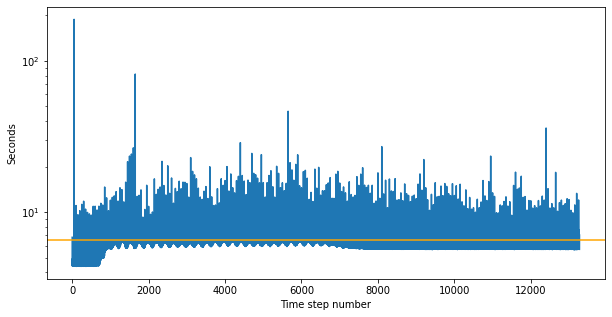

Average timestep duration:  6.497144266988096
/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-24x24x1-Mesh0.434637008855-Mesh0.434637008855-T0e0/lambda800e-9-tau30E-15-field7E8-CEP0.0-StH2/lambda1030e-9-tau30E-15-field1E8-CEP0.0-delay0e-15-StH


In [17]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10,5))
plt.semilogy(results_np[:,0], results_np[:,4])
plt.axhline(np.mean(results_np[:,4]), color="orange")
plt.xlabel("Time step number")
plt.ylabel("Seconds")
plt.savefig("DurationOfTimeStep.eps")
plt.show()
print("Average timestep duration: ", np.mean(results_np[:,4]))
!pwd

# Fetch number of processes for this run

In [18]:
NumProcesses=int(libString.LookUpStringInFile(file, "processes").strip().split()[4])

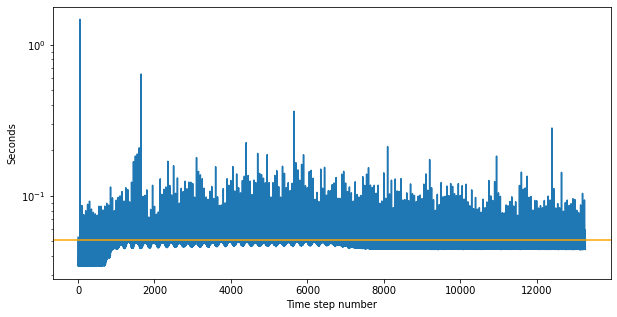

Average timestep duration for 128 threads:  0.0507589395858445


In [19]:
# Plot efficiency from that
plt.figure(figsize=(10,5))
plt.semilogy(results_np[:,0], results_np[:,4]/NumProcesses)
plt.axhline(np.mean(results_np[:,4]/NumProcesses), color="orange")
plt.xlabel("Time step number")
plt.ylabel("Seconds")
plt.savefig("DurationOfTimeStep-NormalizedToNumCores.eps")
plt.show()
print("Average timestep duration for "+str(NumProcesses)+" threads: ", np.mean(results_np[:,4]/NumProcesses))


# Database-wide analysis

In [20]:
DatabasePath=OctopusData+"/03-Bulk3D/"
%cd $DatabasePath

/home/thibault.derrien/Documents/octopus.data/03-Bulk3D


In [21]:
data=pd.read_csv("SiComplete-2023-10-25-BiatriSrv-v2.4-WithToleranceOnField-WithAll.csv", "\t", header=2)
# data=pd.read_csv("2021-02-25-Au-AllData-Database-v2.1.2.csv", "\t", header=2)
# data=pd.read_csv("SiComplete-2023-04-30-BiatriSrv-v2.2.1-WithToleranceOnField-WithAll.csv", "\t", header=2)
# data=pd.read_csv("alpha-SiO2-19-07-2023-AllFinishedRuns.csv", "\t", header=2)
# data=pd.read_csv("Database.csv", "\t", header=2)
datafull=data
data.describe(include="all")
data=data.rename(columns={"##JobID": "JobID"})
datafull=data
data.dtypes

JobID                           float64
Machine                         float64
RunDate                         float64
kgrid                           float64
realmesh                        float64
TimeStep                        float64
lambda1                         float64
tau1                            float64
Efield1                         float64
PolarizationAngle               float64
CEP1                            float64
lambda2                         float64
tau2                            float64
Efield2                         float64
CEP2                            float64
delay                           float64
CrossPolar                      float64
TheoryLevel                     float64
InducedFields                   float64
ProbeFieldAmplitude_AU          float64
ProbeFieldDelay_s               float64
Functional                      float64
FrozenHxc                       float64
MoveIon                         float64
NeMax                           float64


## Overview of results

In [22]:
from octopus_slabs.Libs.libPlotting import MachineNameList, MachineNameHeader
Machine_List = data.Machine.values.tolist()
MachineNameList
Machine_data = [MachineNameList[int(x)] for x in Machine_List]
print(len(Machine_data), len(data.DurationPerTimeStepLastRun), len(data.NumberOfProcesses))

2911 2911 2911


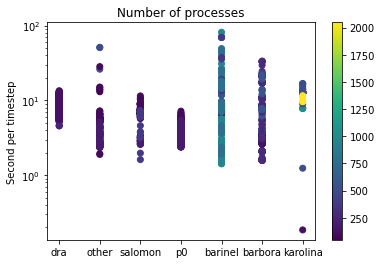

In [23]:
# %matplotlib
plt.figure()
# plt.scatter(Machine_data, data.DurationPerTimeStepLastRun/data.NumberOfProcesses, c=data.PolarizationAngle/np.pi)
plt.scatter(Machine_data, data.DurationPerTimeStepLastRun, c=data.NumberOfProcesses)
plt.yscale("log")
plt.colorbar()
# plt.xlabel("Machines")
plt.title("Number of processes")
plt.ylabel("Second per timestep")
plt.savefig("20230912-Overview.eps")
plt.show()

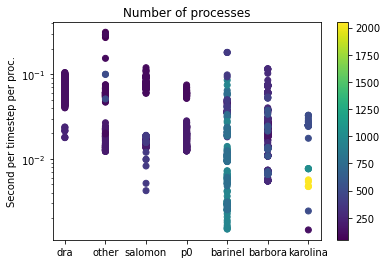

In [24]:
# %matplotlib
plt.figure()
# plt.scatter(Machine_data, data.DurationPerTimeStepLastRun/data.NumberOfProcesses, c=data.PolarizationAngle/np.pi)
plt.scatter(Machine_data, data.DurationPerTimeStepLastRun/data.NumberOfProcesses, c=data.NumberOfProcesses)
plt.yscale("log")
plt.colorbar()
# plt.xlabel("Machines")
plt.title("Number of processes")
plt.ylabel("Second per timestep per proc.")
plt.savefig("20230912-Overview-PerProc.eps")
plt.show()

## Limiting result to precision of k-grid

In [25]:
kgrid_select=40

In [26]:
data=datafull
# data=data[data.Functional==IndexFunctional["TB09"]] #0: LDA, #3: TB09, #2: GGA, #1: MGGA

data=data[data.kgrid==kgrid_select]
# data=data[data.Machine==MachineNameHeader["karolina"]]
data

,JobID,Machine,RunDate,kgrid,realmesh,TimeStep,lambda1,tau1,Efield1,PolarizationAngle,...,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime,DurationPerTimeStepLastRun,NumberOfProcesses
2190,108831.0,4.0,20220210.0,40.0,0.434637,0.25,0.000002,1.118420e-14,3.000000e+09,0.0,...,0.0,5.605595e+26,5.001833e+40,5.012066e+40,1.0,0.0,1875.0,924.740368,21.628475,960.0
2191,107048.0,4.0,20220208.0,40.0,0.434637,0.25,0.000002,1.118420e-14,1.400000e+09,0.0,...,0.0,3.888609e+24,3.240066e+38,3.476877e+38,1.0,0.0,2000.0,924.740368,19.747960,960.0
2192,108832.0,4.0,20220212.0,40.0,0.434637,0.25,0.000002,1.118420e-14,9.000000e+09,0.0,...,0.0,4.725361e+28,4.225342e+42,4.225033e+42,1.0,0.0,1250.0,924.740368,31.085124,960.0
2193,597659.0,5.0,20220309.0,40.0,0.434637,0.25,0.000002,1.118420e-14,1.400000e+09,0.0,...,0.0,0.000000e+00,2.677097e+38,0.000000e+00,5.0,0.0,2000.0,0.000000,10.587850,576.0
2194,598340.0,5.0,20220316.0,40.0,0.434637,0.25,0.000002,2.796053e-14,1.400000e+09,0.0,...,0.0,0.000000e+00,2.005677e+38,0.000000e+00,5.0,0.0,3625.0,0.000000,11.292962,576.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2852,1567455.0,6.0,20221030.0,40.0,0.434637,0.25,0.000002,2.796053e-14,1.400000e+09,0.0,...,0.0,0.000000e+00,3.355341e+42,0.000000e+00,5.0,0.0,3625.0,0.000000,11.569401,2048.0
2854,1561286.0,6.0,20221030.0,40.0,0.434637,0.25,0.000002,2.796053e-14,1.400000e+09,0.0,...,0.0,0.000000e+00,1.536671e+42,0.000000e+00,5.0,0.0,4375.0,0.000000,9.659641,2048.0
2855,1567457.0,6.0,20221030.0,40.0,0.434637,0.25,0.000002,2.796053e-14,1.400000e+09,0.0,...,0.0,0.000000e+00,4.331984e+42,0.000000e+00,5.0,0.0,3875.0,0.000000,10.980266,2048.0
2856,1561289.0,6.0,20221030.0,40.0,0.434637,0.25,0.000002,2.796053e-14,1.400000e+09,0.0,...,0.0,0.000000e+00,4.724222e+42,0.000000e+00,5.0,0.0,4375.0,0.000000,9.765522,2048.0


In [27]:
from octopus_slabs.Libs.libPlotting import MachineNameList, MachineNameHeader
Machine_List = data.Machine.values.tolist()
MachineNameList
Machine_data = [MachineNameList[int(x)] for x in Machine_List]
len(Machine_data)

240

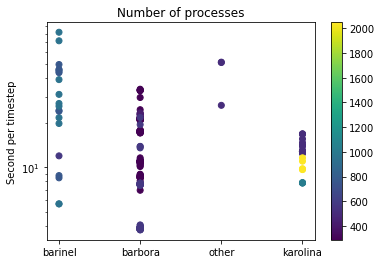

In [28]:
# %matplotlib
plt.figure()
plt.scatter(Machine_data, data.DurationPerTimeStepLastRun, c=data.NumberOfProcesses)
plt.colorbar()
plt.yscale("log")
# plt.xlabel("Machines")
plt.ylabel("Second per timestep")
plt.title("Number of processes")
plt.savefig("20230912-Overview-k"+str(kgrid_select)+".eps")
# plt.show()

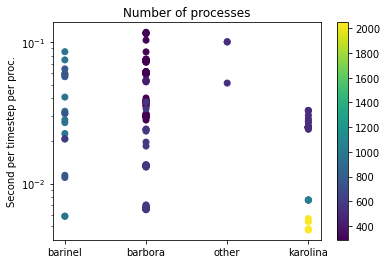

In [29]:
# %matplotlib
plt.figure()
plt.scatter(Machine_data, data.DurationPerTimeStepLastRun/data.NumberOfProcesses, c=data.NumberOfProcesses)
plt.colorbar()
plt.yscale("log")
# plt.xlabel("Machines")
plt.ylabel("Second per timestep per proc.")
plt.title("Number of processes")
plt.savefig("20230912-Overview-k"+str(kgrid_select)+"-PerProc.eps")
# plt.show()

## Analysis of Karolina

Bad luck, with Si, I mostly used Karolina for HHG spectrum computation. Then we don't have much points. And we don't see the effect of capping on the results. 

In [30]:
data=data[data.Machine==MachineNameHeader["karolina"]]
data

,JobID,Machine,RunDate,kgrid,realmesh,TimeStep,lambda1,tau1,Efield1,PolarizationAngle,...,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime,DurationPerTimeStepLastRun,NumberOfProcesses
2201,1640785.0,6.0,20221210.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,0.0,2.376803e+38,0.0,5.0,0.0,3250.00,0.0,12.772745,512.0
2202,1640649.0,6.0,20221209.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,0.0,3.204111e+38,0.0,5.0,0.0,3375.00,0.0,12.698236,512.0
2203,1640774.0,6.0,20221210.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,0.0,2.514440e+38,0.0,5.0,0.0,3375.00,0.0,12.697986,512.0
2204,1640782.0,6.0,20221210.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,0.0,1.502372e+38,0.0,5.0,0.0,3250.00,0.0,12.725015,512.0
2205,1640772.0,6.0,20221210.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,0.0,3.042319e+38,0.0,5.0,0.0,3375.00,0.0,12.670224,512.0
2206,1640778.0,6.0,20221210.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,0.0,1.394709e+38,0.0,5.0,0.0,3250.00,0.0,12.873582,512.0
2207,1640784.0,6.0,20221212.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,0.0,2.005418e+38,0.0,5.0,0.0,5241.25,0.0,12.352458,512.0
2208,1640775.0,6.0,20221210.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,0.0,2.199706e+38,0.0,5.0,0.0,3250.00,0.0,12.768047,512.0
2209,1640790.0,6.0,20221210.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,0.0,3.277580e+38,0.0,5.0,0.0,3375.00,0.0,12.679607,512.0
2210,1640780.0,6.0,20221210.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,0.0,1.244067e+38,0.0,5.0,0.0,3375.00,0.0,12.708560,512.0


In [31]:
from octopus_slabs.Libs.libPlotting import MachineNameList
Machine_List = data.Machine.values.tolist()
MachineNameList
Machine_data = [MachineNameList[int(x)] for x in Machine_List]
data['Efficiency']=data.DurationPerTimeStepLastRun/data.NumberOfProcesses

/home/thibault.derrien/.local/lib/python3.6/site-packages/ipykernel_launcher.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  """


In [32]:
len(Machine_data)

52

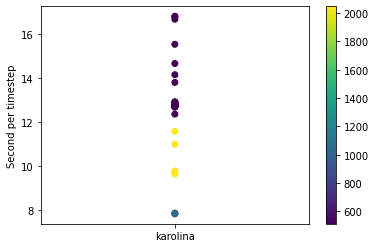

In [33]:
# %matplotlib
plt.figure()
plt.scatter(Machine_data, data.DurationPerTimeStepLastRun, c=(data.NumberOfProcesses))
plt.colorbar()
# plt.yscale("log")
# plt.xlabel("Machines")
plt.ylabel("Second per timestep")
plt.savefig("20230912-Overview-k"+str(kgrid_select)+"-Karolina.eps")
plt.show()

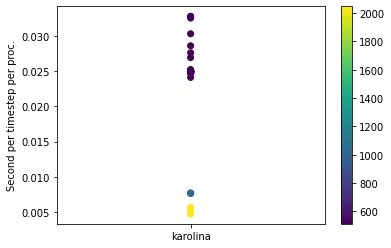

In [34]:
# %matplotlib
plt.figure()
plt.scatter(Machine_data, data.DurationPerTimeStepLastRun/data.NumberOfProcesses, c=(data.NumberOfProcesses))
plt.colorbar()
# plt.yscale("log")
# plt.xlabel("Machines")
plt.ylabel("Second per timestep per proc.")
plt.savefig("20230912-Overview-k"+str(kgrid_select)+"-PerProc-Karolina.eps")
plt.show()

This result suggests that upscale can work beyond since processor time for 1 timestep is still decreasing while increasing number of processors. The load per processor is then decreasing upon increasing communication. 

### Accounting for processor frequency capping date

In [35]:
import datetime
DateOfProcessorCapping=20230201
DateOfProcessorCapping_date=datetime.datetime(2023, 2, 1)

In [36]:
import matplotlib.dates as mdates
from datetime import datetime
dates = [datetime.strptime(str(int(date)), '%Y%m%d') for date in data.RunDate]

In [37]:
dates_capped_runs = [((date - DateOfProcessorCapping_date).days > 0) for date in dates]

In [38]:
# dates_capped_runs

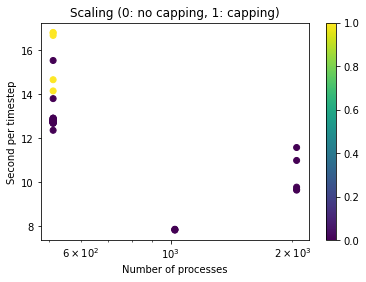

In [39]:
# %matplotlib
# plt.figure(figsize=(5,5))
# plt.scatter(Machine_data, data.DurationPerTimeStepLastRun/data.NumberOfProcesses, c=data.PolarizationAngle/np.pi)
plt.scatter(data.NumberOfProcesses, data.DurationPerTimeStepLastRun, c=dates_capped_runs)
plt.xscale("log")
plt.colorbar()
# plt.legend()
plt.xlabel("Number of processes")
plt.title("Scaling (0: no capping, 1: capping)")
plt.ylabel("Second per timestep")
plt.savefig("20230912-Overview-k"+str(kgrid_select)+"-Karolina-Scaling.eps")
plt.show()

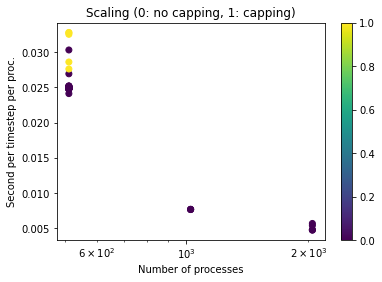

In [40]:
# %matplotlib
# plt.figure(figsize=(5,5))
# plt.scatter(Machine_data, data.DurationPerTimeStepLastRun/data.NumberOfProcesses, c=data.PolarizationAngle/np.pi)
plt.scatter(data.NumberOfProcesses, data.DurationPerTimeStepLastRun/data.NumberOfProcesses, c=dates_capped_runs)
plt.xscale("log")
plt.colorbar()
# plt.legend()
plt.xlabel("Number of processes")
plt.title("Scaling (0: no capping, 1: capping)")
plt.ylabel("Second per timestep per proc.")
plt.savefig("20230912-Overview-k"+str(kgrid_select)+"-Karolina-Scaling-PerProc.eps")
plt.show()

This result shows that scaling may not be so good if using 2048 cores. 
Capping 

In [41]:
data

,JobID,Machine,RunDate,kgrid,realmesh,TimeStep,lambda1,tau1,Efield1,PolarizationAngle,...,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime,DurationPerTimeStepLastRun,NumberOfProcesses,Efficiency
2201,1640785.0,6.0,20221210.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,2.376803e+38,0.0,5.0,0.0,3250.00,0.0,12.772745,512.0,0.024947
2202,1640649.0,6.0,20221209.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,3.204111e+38,0.0,5.0,0.0,3375.00,0.0,12.698236,512.0,0.024801
2203,1640774.0,6.0,20221210.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,2.514440e+38,0.0,5.0,0.0,3375.00,0.0,12.697986,512.0,0.024801
2204,1640782.0,6.0,20221210.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,1.502372e+38,0.0,5.0,0.0,3250.00,0.0,12.725015,512.0,0.024854
2205,1640772.0,6.0,20221210.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,3.042319e+38,0.0,5.0,0.0,3375.00,0.0,12.670224,512.0,0.024747
2206,1640778.0,6.0,20221210.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,1.394709e+38,0.0,5.0,0.0,3250.00,0.0,12.873582,512.0,0.025144
2207,1640784.0,6.0,20221212.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,2.005418e+38,0.0,5.0,0.0,5241.25,0.0,12.352458,512.0,0.024126
2208,1640775.0,6.0,20221210.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,2.199706e+38,0.0,5.0,0.0,3250.00,0.0,12.768047,512.0,0.024938
2209,1640790.0,6.0,20221210.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,3.277580e+38,0.0,5.0,0.0,3375.00,0.0,12.679607,512.0,0.024765
2210,1640780.0,6.0,20221210.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,1.244067e+38,0.0,5.0,0.0,3375.00,0.0,12.708560,512.0,0.024821


In [42]:
data.RunDate

2201    20221210.0
2202    20221209.0
2203    20221210.0
2204    20221210.0
2205    20221210.0
2206    20221210.0
2207    20221212.0
2208    20221210.0
2209    20221210.0
2210    20221210.0
2211    20221210.0
2212    20221210.0
2213    20221210.0
2214    20221210.0
2215    20221210.0
2216    20221210.0
2217    20221210.0
2218    20221210.0
2219    20221210.0
2220    20221210.0
2221    20221210.0
2222    20221214.0
2223    20230124.0
2224    20230201.0
2225    20230130.0
2226    20230130.0
2227    20230130.0
2228    20230129.0
2229    20230130.0
2230    20230129.0
2231    20230130.0
2232    20230129.0
2233    20230129.0
2234    20230130.0
2235    20230130.0
2236    20230129.0
2237    20230130.0
2238    20230130.0
2239    20230129.0
2240    20230129.0
2241    20230130.0
2242    20230203.0
2243    20230130.0
2244    20230209.0
2245    20230206.0
2246    20230206.0
2247    20230725.0
2852    20221030.0
2854    20221030.0
2855    20221030.0
2856    20221030.0
2857    20221025.0
Name: RunDat

### Checking effect of capping for a chosen number of processors

In [43]:
data=data[data.NumberOfProcesses==512]

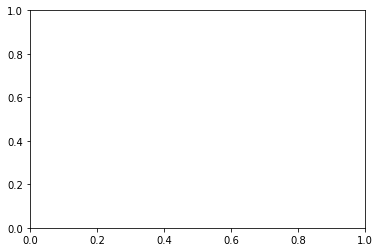

In [44]:
import matplotlib.dates as mdates
from datetime import datetime
fig, ax = plt.subplots()
dates = [datetime.strptime(str(int(date)), '%Y%m%d') for date in data.RunDate]


In [45]:
# print(dates)
# print(DateOfProcessorCapping_date)

In [46]:
dates_since_cap = [(date - DateOfProcessorCapping_date).days for date in dates]
dates_capped_runs = [((date - DateOfProcessorCapping_date).days > 0) for date in dates]
# print(dates_since_cap)

In [47]:
data

,JobID,Machine,RunDate,kgrid,realmesh,TimeStep,lambda1,tau1,Efield1,PolarizationAngle,...,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime,DurationPerTimeStepLastRun,NumberOfProcesses,Efficiency
2201,1640785.0,6.0,20221210.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,2.376803e+38,0.0,5.0,0.0,3250.00,0.0,12.772745,512.0,0.024947
2202,1640649.0,6.0,20221209.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,3.204111e+38,0.0,5.0,0.0,3375.00,0.0,12.698236,512.0,0.024801
2203,1640774.0,6.0,20221210.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,2.514440e+38,0.0,5.0,0.0,3375.00,0.0,12.697986,512.0,0.024801
2204,1640782.0,6.0,20221210.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,1.502372e+38,0.0,5.0,0.0,3250.00,0.0,12.725015,512.0,0.024854
2205,1640772.0,6.0,20221210.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,3.042319e+38,0.0,5.0,0.0,3375.00,0.0,12.670224,512.0,0.024747
2206,1640778.0,6.0,20221210.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,1.394709e+38,0.0,5.0,0.0,3250.00,0.0,12.873582,512.0,0.025144
2207,1640784.0,6.0,20221212.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,2.005418e+38,0.0,5.0,0.0,5241.25,0.0,12.352458,512.0,0.024126
2208,1640775.0,6.0,20221210.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,2.199706e+38,0.0,5.0,0.0,3250.00,0.0,12.768047,512.0,0.024938
2209,1640790.0,6.0,20221210.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,3.277580e+38,0.0,5.0,0.0,3375.00,0.0,12.679607,512.0,0.024765
2210,1640780.0,6.0,20221210.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,1.244067e+38,0.0,5.0,0.0,3375.00,0.0,12.708560,512.0,0.024821


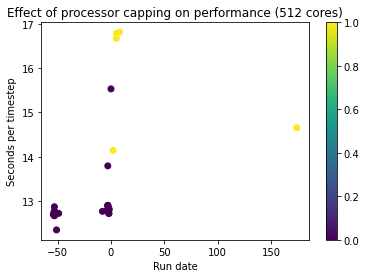

In [48]:
plt.scatter(dates_since_cap, data.DurationPerTimeStepLastRun, c=dates_capped_runs)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y%m%d')) #this gonna be solved when NEW DB is ready
plt.colorbar()
plt.title("Effect of processor capping on performance (512 cores)")
plt.xlabel("Run date")
plt.ylabel("Seconds per timestep")
plt.savefig("20230912-Overview-k"+str(kgrid_select)+"-Karolina-CappingEffect.eps")
plt.show()

In [49]:
print(100*(13.8-14.2)/14.2)
print(100*(15.5-16.8)/15.5)

-2.8169014084506943
-8.387096774193552


We look at data prepared AFTER processor capping. 

In [50]:
data_tmp = data[data.RunDate >= DateOfProcessorCapping]
data_tmp2 = data_tmp[data_tmp.DurationPerTimeStepLastRun < 8] 

In [51]:
data_tmp

,JobID,Machine,RunDate,kgrid,realmesh,TimeStep,lambda1,tau1,Efield1,PolarizationAngle,...,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime,DurationPerTimeStepLastRun,NumberOfProcesses,Efficiency
2224,1727804.0,6.0,20230201.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,3.019177e+38,0.0,5.0,0.0,4250.00,0.0,15.530089,512.0,0.030332
2242,1727802.0,6.0,20230203.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.400000e+09,0.0,...,0.0,2.466588e+38,0.0,5.0,0.0,5241.25,0.0,14.144732,512.0,0.027626
2244,1737887.0,6.0,20230209.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.600000e+09,0.0,...,0.0,7.015069e+38,0.0,5.0,0.0,3250.00,0.0,16.806709,512.0,0.032826
2245,1738063.0,6.0,20230206.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.600000e+09,0.0,...,0.0,6.831269e+38,0.0,5.0,0.0,3125.00,0.0,16.782955,512.0,0.032779
2246,1738064.0,6.0,20230206.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.600000e+09,0.0,...,0.0,4.839893e+38,0.0,5.0,0.0,3000.00,0.0,16.671264,512.0,0.032561
2247,1982079.0,6.0,20230725.0,40.0,0.434637,0.25,0.000002,3.355000e-14,1.600000e+09,0.0,...,0.0,1.062828e+39,0.0,5.0,0.0,4375.00,0.0,14.655156,512.0,0.028623


## Analysis of Barbora

In [52]:
from octopus_slabs.Libs.libPlotting import MachineNameList, MachineNameHeader

kgrid_select=40

data=datafull
data=data[data.kgrid==kgrid_select]
data=data[data.Machine==MachineNameHeader["barbora"]]

Machine_List = data.Machine.values.tolist()
MachineNameList
Machine_data = [MachineNameList[int(x)] for x in Machine_List]
data

,JobID,Machine,RunDate,kgrid,realmesh,TimeStep,lambda1,tau1,Efield1,PolarizationAngle,...,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime,DurationPerTimeStepLastRun,NumberOfProcesses
2193,597659.0,5.0,20220309.0,40.0,0.434637,0.25,0.000002,1.118420e-14,1.400000e+09,0.000000,...,0.0,0.000000e+00,2.677097e+38,0.000000e+00,5.0,0.0,2000.0,0.000000,10.587850,576.0
2194,598340.0,5.0,20220316.0,40.0,0.434637,0.25,0.000002,2.796053e-14,1.400000e+09,0.000000,...,0.0,0.000000e+00,2.005677e+38,0.000000e+00,5.0,0.0,3625.0,0.000000,11.292962,576.0
2647,586197.0,5.0,20211221.0,40.0,0.434637,0.25,0.000003,1.394500e-14,3.000000e+09,0.753982,...,0.0,2.473146e+27,1.773881e+41,1.773500e+41,1.0,0.0,1875.0,1153.010893,22.655291,432.0
2648,528466.0,5.0,20210929.0,40.0,0.434637,0.25,0.000003,1.394500e-14,3.000000e+09,0.125664,...,0.0,2.018731e+27,1.447718e+41,1.447638e+41,1.0,0.0,1250.0,1153.010893,33.238567,288.0
2649,586193.0,5.0,20211220.0,40.0,0.434637,0.25,0.000003,1.394500e-14,3.000000e+09,0.502655,...,0.0,2.374915e+27,1.703422e+41,1.703058e+41,1.0,0.0,1750.0,1153.010893,23.097841,432.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2820,520137.0,5.0,20210919.0,40.0,0.434637,0.25,0.000003,1.394500e-14,3.000000e+09,0.471239,...,0.0,2.347336e+27,1.683482e+41,1.683282e+41,1.0,0.0,1500.0,1153.010893,13.794876,576.0
2821,586196.0,5.0,20211221.0,40.0,0.434637,0.25,0.000003,1.394500e-14,3.000000e+09,0.691150,...,0.0,2.454259e+27,1.760294e+41,1.759957e+41,1.0,0.0,1750.0,1153.010893,23.290733,432.0
2822,528467.0,5.0,20210929.0,40.0,0.434637,0.25,0.000003,1.394500e-14,3.000000e+09,0.188496,...,0.0,2.059679e+27,1.477081e+41,1.477002e+41,1.0,0.0,1250.0,1153.010893,33.221494,288.0
2825,597660.0,5.0,20220310.0,40.0,0.434637,0.25,0.000002,1.118420e-14,1.400000e+09,0.785398,...,0.0,0.000000e+00,5.949421e+38,0.000000e+00,5.0,0.0,1500.0,0.000000,19.407831,576.0


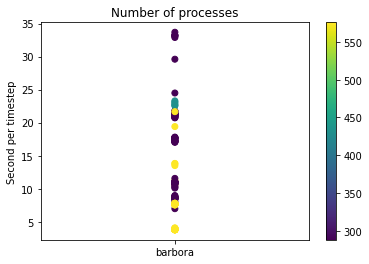

In [53]:
# %matplotlib
plt.figure()
plt.scatter(Machine_data, data.DurationPerTimeStepLastRun, c=(data.NumberOfProcesses))
plt.colorbar()
# plt.yscale("log")
# plt.xlabel("Machines")
plt.ylabel("Second per timestep")
plt.title("Number of processes")
plt.savefig("20230912-Overview-k"+str(kgrid_select)+"-Barbora.eps")
plt.show()

In [54]:
# Create a reverse dictionnary
from octopus_slabs.Libs.libPlotting import IndexFunctional
IndexFunctional_rev = {value: key for key, value in IndexFunctional.items()}
print(IndexFunctional_rev)

{0: 'LDA', 3: 'TB09', 2: 'GGA', 1: 'MGGA'}


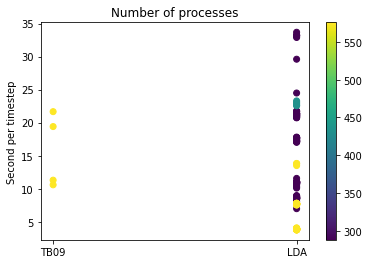

In [55]:
Functional_List = data.Functional.values.tolist()
Functional_Data = [IndexFunctional_rev[int(x)] for x in Functional_List]

# %matplotlib
plt.figure()
plt.scatter(Functional_Data, data.DurationPerTimeStepLastRun, c=(data.NumberOfProcesses))
plt.colorbar()
# plt.yscale("log")
# plt.xlabel("Machines")
plt.ylabel("Second per timestep")
plt.title("Number of processes")
plt.savefig("20230912-Overview-k"+str(kgrid_select)+"-Barbora-Functional.eps")
plt.show()

In [56]:
data = data[data.Functional == IndexFunctional["LDA"]]
data

,JobID,Machine,RunDate,kgrid,realmesh,TimeStep,lambda1,tau1,Efield1,PolarizationAngle,...,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime,DurationPerTimeStepLastRun,NumberOfProcesses
2647,586197.0,5.0,20211221.0,40.0,0.434637,0.25,0.000003,1.394500e-14,3.000000e+09,0.753982,...,0.0,2.473146e+27,1.773881e+41,1.773500e+41,1.0,0.0,1875.0,1153.010893,22.655291,432.0
2648,528466.0,5.0,20210929.0,40.0,0.434637,0.25,0.000003,1.394500e-14,3.000000e+09,0.125664,...,0.0,2.018731e+27,1.447718e+41,1.447638e+41,1.0,0.0,1250.0,1153.010893,33.238567,288.0
2649,586193.0,5.0,20211220.0,40.0,0.434637,0.25,0.000003,1.394500e-14,3.000000e+09,0.502655,...,0.0,2.374915e+27,1.703422e+41,1.703058e+41,1.0,0.0,1750.0,1153.010893,23.097841,432.0
2650,527844.0,5.0,20210929.0,40.0,0.434637,0.25,0.000003,1.394500e-14,3.000000e+09,0.062832,...,0.0,1.986689e+27,1.424753e+41,1.424660e+41,1.0,0.0,1250.0,1153.010893,33.685173,288.0
2651,528470.0,5.0,20210930.0,40.0,0.434637,0.25,0.000003,1.394500e-14,3.000000e+09,0.439823,...,0.0,2.309797e+27,1.656421e+41,1.656362e+41,1.0,0.0,1250.0,1153.010893,32.892547,288.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2818,516077.0,5.0,20210912.0,40.0,0.434637,0.25,0.000003,1.394500e-14,3.000000e+09,0.157080,...,0.0,2.038333e+27,1.461907e+41,1.461694e+41,1.0,0.0,1500.0,1153.010893,13.502837,576.0
2819,520136.0,5.0,20210919.0,40.0,0.434637,0.25,0.000003,1.394500e-14,3.000000e+09,0.314159,...,0.0,2.169291e+27,1.555847e+41,1.555605e+41,1.0,0.0,1500.0,1153.010893,13.826245,576.0
2820,520137.0,5.0,20210919.0,40.0,0.434637,0.25,0.000003,1.394500e-14,3.000000e+09,0.471239,...,0.0,2.347336e+27,1.683482e+41,1.683282e+41,1.0,0.0,1500.0,1153.010893,13.794876,576.0
2821,586196.0,5.0,20211221.0,40.0,0.434637,0.25,0.000003,1.394500e-14,3.000000e+09,0.691150,...,0.0,2.454259e+27,1.760294e+41,1.759957e+41,1.0,0.0,1750.0,1153.010893,23.290733,432.0


### Effect of polarization angle

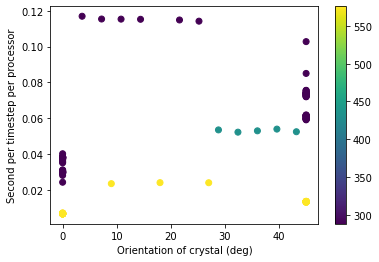

In [57]:
# %matplotlib
plt.figure()
plt.scatter(data.PolarizationAngle/np.pi*180., data.DurationPerTimeStepLastRun/data.NumberOfProcesses, c=(data.NumberOfProcesses))
plt.colorbar()
# plt.yscale("log")
plt.xlabel("Orientation of crystal (deg)")
plt.ylabel("Second per timestep per processor")
plt.savefig("20230912-Overview-k"+str(kgrid_select)+"-Barbora-LDA-Orientation.eps")
plt.show()

### Exploring dispersion at given angle

In [58]:
from scipy.constants import pi
data=data[data.PolarizationAngle==0.7853981634]
# set(data.PolarizationAngle)
data.std(axis=0)

JobID                           2.546749e+04
Machine                         0.000000e+00
RunDate                         4.457746e+03
kgrid                           0.000000e+00
realmesh                        3.357422e-16
TimeStep                        0.000000e+00
lambda1                         1.707673e-21
tau1                            2.840157e-15
Efield1                         3.959735e+09
PolarizationAngle               1.342969e-15
CEP1                            9.588044e-01
lambda2                         1.707673e-21
tau2                            2.840157e-15
Efield2                         0.000000e+00
CEP2                            9.588044e-01
delay                           8.836572e-17
CrossPolar                      1.342969e-15
TheoryLevel                     0.000000e+00
InducedFields                   0.000000e+00
ProbeFieldAmplitude_AU          0.000000e+00
ProbeFieldDelay_s                        NaN
Functional                      0.000000e+00
FrozenHxc 

In [59]:
set(data.realmesh)

{0.4346370089}

## Analysis for Navigator / Barinel

In [60]:
data = datafull #restoring initial database

In [61]:
from octopus_slabs.Libs.libPlotting import MachineNameList, MachineNameHeader

kgrid_select=24

data=datafull
data=data[data.kgrid==kgrid_select]
data=data[data.Machine==MachineNameHeader["barinel"]]


In [62]:
# Select one direction of orientation
data = data[data.PolarizationAngle == 0]
# Select only LDA or TB09
data = data[data.Functional == IndexFunctional["LDA"]]
# Select the k-grid resolution
data = data[data.kgrid == 24]
# Select the real mesh resolution
data = data[data.realmesh > 0.43]
# Select single pulse runs
data = data[data.Efield2 < 0.1]


In [63]:
data

,JobID,Machine,RunDate,kgrid,realmesh,TimeStep,lambda1,tau1,Efield1,PolarizationAngle,...,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime,DurationPerTimeStepLastRun,NumberOfProcesses
2513,106459.0,4.0,20211225.0,24.0,0.434637,0.25,0.000001,2.000000e-14,6.000000e+08,0.0,...,0.0,6.172253e+24,2.875390e+38,3.086127e+38,3.0,2.0,2231.25,968.864436,6.820586,192.0
2514,106452.0,4.0,20211224.0,24.0,0.434637,0.25,0.000001,2.000000e-14,2.000000e+08,0.0,...,0.0,6.776880e+22,1.327288e+36,3.388440e+36,3.0,2.0,2231.25,968.864436,6.726109,192.0
2515,106488.0,4.0,20211224.0,24.0,0.434637,0.25,0.000001,2.000000e-14,4.000000e+08,0.0,...,0.0,8.618346e+23,3.343493e+37,4.309173e+37,3.0,2.0,2231.25,968.864436,6.778170,192.0
2516,106490.0,4.0,20211225.0,24.0,0.434637,0.25,0.000001,2.000000e-14,5.500000e+08,0.0,...,0.0,3.980434e+24,1.810363e+38,1.990217e+38,3.0,2.0,2231.25,968.864436,6.884735,192.0
2517,106507.0,4.0,20211227.0,24.0,0.434637,0.25,0.000001,2.000000e-14,8.500000e+09,0.0,...,0.0,7.231500e+28,3.613167e+42,3.615750e+42,3.0,2.0,2231.25,968.864436,9.391243,192.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2580,253867.0,4.0,20221120.0,24.0,0.434637,0.25,0.000001,4.980469e-14,1.730000e+09,0.0,...,0.0,9.045808e+26,1.813850e+40,1.816256e+40,1.0,0.0,5290.00,4117.988325,3.891844,768.0
2581,300868.0,4.0,20221203.0,24.0,0.434637,0.25,0.000001,4.980469e-14,2.000000e+09,0.0,...,0.0,1.735543e+27,3.479507e+40,3.484699e+40,1.0,0.0,5290.00,4117.988325,3.668010,768.0
2582,300931.0,4.0,20221214.0,24.0,0.434637,0.25,0.000001,4.980469e-14,4.000000e+09,0.0,...,0.0,1.590423e+28,3.193353e+41,3.193320e+41,1.0,0.0,5290.00,4117.988325,2.154329,768.0
2583,300932.0,4.0,20221217.0,24.0,0.434637,0.25,0.000001,4.980469e-14,5.000000e+09,0.0,...,0.0,2.914597e+28,5.851200e+41,5.852053e+41,1.0,0.0,4875.00,4117.988325,2.286738,768.0


In [64]:
Machine_List = data.Machine.values.tolist()
MachineNameList
Machine_data = [MachineNameList[int(x)] for x in Machine_List]

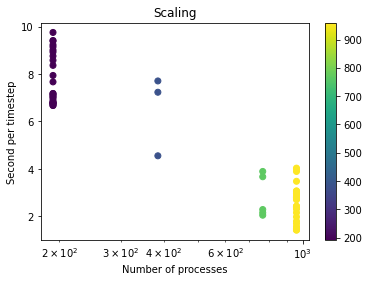

In [65]:
# %matplotlib
# plt.figure(figsize=(5,5))
# plt.scatter(Machine_data, data.DurationPerTimeStepLastRun/data.NumberOfProcesses, c=data.PolarizationAngle/np.pi)
plt.scatter(data.NumberOfProcesses, data.DurationPerTimeStepLastRun, c=data.NumberOfProcesses)
plt.xscale("log")
plt.colorbar()
# plt.legend()
plt.xlabel("Number of processes")
plt.title("Scaling")
plt.ylabel("Second per timestep")
plt.savefig("20230912-Overview-k"+str(kgrid_select)+"-Barinel-Scaling.eps")
plt.show()

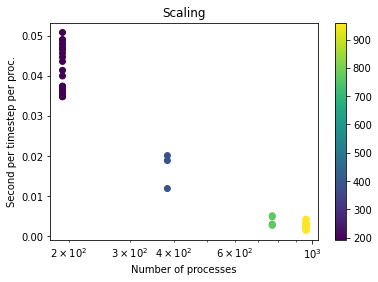

In [66]:
# %matplotlib
# plt.figure(figsize=(5,5))
# plt.scatter(Machine_data, data.DurationPerTimeStepLastRun/data.NumberOfProcesses, c=data.PolarizationAngle/np.pi)
plt.scatter(data.NumberOfProcesses, data.DurationPerTimeStepLastRun/data.NumberOfProcesses, c=data.NumberOfProcesses)
plt.xscale("log")
plt.colorbar()
# plt.legend()
plt.xlabel("Number of processes")
plt.title("Scaling")
plt.ylabel("Second per timestep per proc.")
plt.savefig("20230912-Overview-k"+str(kgrid_select)+"-Barinel-Scaling-PerProc.eps")
plt.show()

## Effect of choice of supercomputer

In [67]:
kgrid_select = 24

data = datafull #restoring initial database
# Select one direction of orientation
data = data[data.PolarizationAngle == 0]
# Select only LDA or TB09
data = data[data.Functional == IndexFunctional["TB09"]]
# Select the k-grid resolution
data = data[data.kgrid == kgrid_select]
# Select the real mesh resolution
data = data[data.realmesh > 0.43]
# Select single pulse runs
data = data[data.Efield2 < 0.1]

In [68]:
Machine_List = data.Machine.values.tolist()
MachineNameList
Machine_data = [MachineNameList[int(x)] for x in Machine_List]
print(len(Machine_data), len(data.DurationPerTimeStepLastRun), len(data.NumberOfProcesses))

18 18 18


In [69]:
data

,JobID,Machine,RunDate,kgrid,realmesh,TimeStep,lambda1,tau1,Efield1,PolarizationAngle,...,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime,DurationPerTimeStepLastRun,NumberOfProcesses
2190,108831.0,4.0,20220210.0,40.0,0.434637,0.25,2.237000e-06,1.118420e-14,3.000000e+09,0.0,...,0.0,5.605595e+26,5.001833e+40,5.012066e+40,1.0,0.0,1875.00,924.740368,21.628475,960.0
2191,107048.0,4.0,20220208.0,40.0,0.434637,0.25,2.237000e-06,1.118420e-14,1.400000e+09,0.0,...,0.0,3.888609e+24,3.240066e+38,3.476877e+38,1.0,0.0,2000.00,924.740368,19.747960,960.0
2192,108832.0,4.0,20220212.0,40.0,0.434637,0.25,2.237000e-06,1.118420e-14,9.000000e+09,0.0,...,0.0,4.725361e+28,4.225342e+42,4.225033e+42,1.0,0.0,1250.00,924.740368,31.085124,960.0
2193,597659.0,5.0,20220309.0,40.0,0.434637,0.25,2.237000e-06,1.118420e-14,1.400000e+09,0.0,...,0.0,0.000000e+00,2.677097e+38,0.000000e+00,5.0,0.0,2000.00,0.000000,10.587850,576.0
2194,598340.0,5.0,20220316.0,40.0,0.434637,0.25,2.237000e-06,2.796053e-14,1.400000e+09,0.0,...,0.0,0.000000e+00,2.005677e+38,0.000000e+00,5.0,0.0,3625.00,0.000000,11.292962,576.0
2195,224172.0,4.0,20220724.0,40.0,0.434637,0.25,8.388158e-07,6.710526e-15,1.400000e+09,0.0,...,0.0,0.000000e+00,5.859370e+39,0.000000e+00,5.0,0.0,875.00,0.000000,24.172010,768.0
2196,42838.0,-1.0,20220803.0,40.0,0.434637,0.25,8.388158e-07,6.710526e-15,2.000000e+09,0.0,...,0.0,0.000000e+00,2.240096e+40,0.000000e+00,5.0,0.0,1000.00,0.000000,26.205319,512.0
2197,229542.0,4.0,20220816.0,40.0,0.434637,0.25,8.388158e-07,6.710526e-15,2.000000e+09,0.0,...,0.0,0.000000e+00,2.238991e+40,0.000000e+00,5.0,0.0,1183.75,0.000000,23.908121,768.0
2198,229541.0,4.0,20220816.0,40.0,0.434637,0.25,8.388158e-07,6.710526e-15,1.400000e+09,0.0,...,0.0,0.000000e+00,5.857683e+39,0.000000e+00,5.0,0.0,875.00,0.000000,45.766866,768.0
2199,228211.0,4.0,20220810.0,40.0,0.434637,0.25,8.388158e-07,6.710526e-15,2.000000e+09,0.0,...,0.0,0.000000e+00,2.242668e+40,0.000000e+00,5.0,0.0,625.00,0.000000,49.510762,768.0


In [70]:
data.std(axis=0)

JobID                           6.940166e+05
Machine                         1.685191e+00
RunDate                         2.239176e+03
kgrid                           0.000000e+00
realmesh                        1.713615e-16
TimeStep                        0.000000e+00
lambda1                         6.782190e-07
tau1                            1.092342e-14
Efield1                         1.793416e+09
PolarizationAngle               0.000000e+00
CEP1                            6.068493e-01
lambda2                         6.782190e-07
tau2                            1.092342e-14
Efield2                         0.000000e+00
CEP2                            6.068493e-01
delay                           0.000000e+00
CrossPolar                      0.000000e+00
TheoryLevel                     0.000000e+00
InducedFields                   0.000000e+00
ProbeFieldAmplitude_AU          0.000000e+00
ProbeFieldDelay_s                        NaN
Functional                      0.000000e+00
FrozenHxc 

In [71]:
FunctionalName=IndexFunctional_rev[list(set(data.Functional))[0]]
print(FunctionalName)

TB09


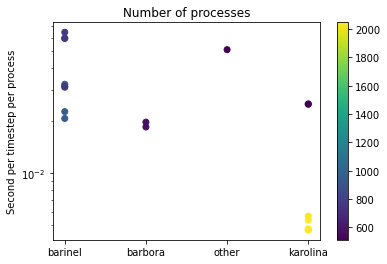

In [72]:
# %matplotlib
plt.figure()
# plt.scatter(Machine_data, data.DurationPerTimeStepLastRun/data.NumberOfProcesses, c=data.PolarizationAngle/np.pi)
plt.scatter(Machine_data, data.DurationPerTimeStepLastRun/data.NumberOfProcesses, c=data.NumberOfProcesses)
plt.yscale("log")
plt.colorbar()
# plt.xlabel("Machines")
# plt.title("Induced field or not?")
plt.title("Number of processes")
plt.ylabel("Second per timestep per process")
plt.savefig("20230915-Overview-Filtered-k"+str(kgrid_select)+"-InducedFields-"+str(FunctionalName)+".eps")
plt.show()

In [73]:
data = data[data.InducedFields == 0]
data = data[data.MoveIon == 0]
Machine_List = data.Machine.values.tolist()
MachineNameList
Machine_data = [MachineNameList[int(x)] for x in Machine_List]
print(len(Machine_data), len(data.DurationPerTimeStepLastRun), len(data.NumberOfProcesses))

18 18 18


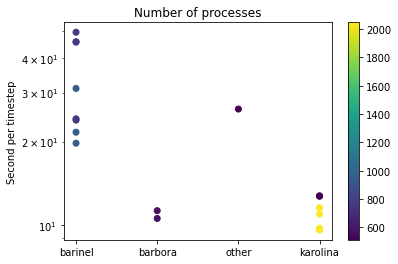

In [74]:
# %matplotlib
plt.figure()
# plt.scatter(Machine_data, data.DurationPerTimeStepLastRun/data.NumberOfProcesses, c=data.PolarizationAngle/np.pi)
plt.scatter(Machine_data, data.DurationPerTimeStepLastRun, c=data.NumberOfProcesses)
plt.yscale("log")
plt.colorbar()
# plt.xlabel("Machines")
plt.title("Number of processes")
plt.ylabel("Second per timestep")
plt.savefig("20230915-Overview-Multimachines-Filtered-k"+str(kgrid_select)+"-"+str(FunctionalName)+".eps")
plt.show()

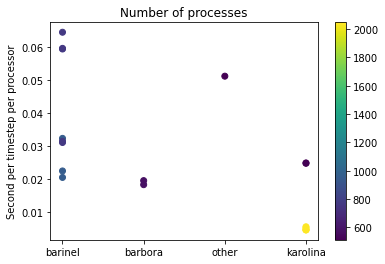

In [75]:
# %matplotlib
plt.figure()
plt.scatter(Machine_data, data.DurationPerTimeStepLastRun/data.NumberOfProcesses, c=data.NumberOfProcesses)
# plt.scatter(Machine_data, data.DurationPerTimeStepLastRun, c=data.NumberOfProcesses)
# plt.yscale("log")
plt.colorbar()
# plt.xlabel("Machines")
plt.title("Number of processes")
plt.ylabel("Second per timestep per processor")
plt.savefig("20230915-Overview-Multimachines-Filtered-k"+str(kgrid_select)+"-PerProc-"+str(FunctionalName)+".eps")
plt.show()